# 704. Binary Search
**Difficulty:** 🟢 Easy · **Topic:** Binary Search · **Pattern:** [Sorted Search](README.md) · **LeetCode:** https://leetcode.com/problems/binary-search/

## 💡 Concepts

**Core concept(s):** **Binary search** on a sorted array — compare the target with the middle element and throw away the half that cannot contain it.

**Why it applies here:**
- The array is **sorted ascending**, so one comparison with `nums[mid]` tells you which side of `mid` the target must be on.
- The problem demands `O(log n)` time, which rules out reading every element.

**Key intuition:**
- Keep a search space `[lo, hi]` that always contains the target if the target exists at all.
- Each step looks at the middle and shrinks the space to one half, excluding `mid` itself.
- When the space is empty (`lo > hi`), the target is not in the array.

---

### 📚 What is a Linear Scan?
- A **linear scan** reads the elements one by one from the start until it finds the target or runs out.
- It works on any array, sorted or not, because it never uses the order.
- **Complexity:** `O(n)` time in the worst case (target absent or last), `O(1)` extra space.
- **In Python:** a `for i, x in enumerate(nums)` loop (or `nums.index(target)`, which does the same scan).

### 📚 What is Binary Search?
- **Binary search** finds a value in a **sorted** sequence by repeatedly halving the part that can still contain it.
- **Mental picture:** guessing a number between 1 and 100 with "higher / lower" hints. Guessing the middle each time needs at most 7 guesses.
- **How it works:**
  1. Start with `lo = 0`, `hi = len(nums) - 1`: the whole array is the search space.
  2. Look at `mid = lo + (hi - lo) // 2`.
  3. Equal → found. Too small → the target is to the right, so `lo = mid + 1`. Too big → it is to the left, so `hi = mid - 1`.
  4. Stop when `lo > hi`: the search space is empty.
- **Complexity:** each step halves the space, so at most about `log₂ n + 1` steps → **`O(log n)`** time, **`O(1)`** extra space.
- **Invariant:** if the target is anywhere in the array, it is inside `nums[lo..hi]`. Moving to `mid ± 1` (never just `mid`) keeps the invariant and guarantees the space shrinks every step.
- **In Python:** written by hand as below, or the standard library's `bisect.bisect_left(nums, target)`, which returns the first index whose value is `>= target`.

---

**Prerequisite knowledge:**
- Zero-based array indexing.
- Integer division `//` (rounds down).

## 📝 Problem

Given an array of integers `nums` sorted in **ascending** order and an integer `target`, return the **index** of `target` in `nums`, or `-1` if it is not there. The algorithm must run in `O(log n)` time.

**Example 1**
```
nums = [-1, 0, 3, 5, 9, 12], target = 9   ->  4      (nums[4] == 9)
```

**Example 2**
```
nums = [-1, 0, 3, 5, 9, 12], target = 2   ->  -1     (2 is not in nums)
```

**Constraints:** `1 <= nums.length <= 10⁴`, `-10⁴ < nums[i], target < 10⁴`, all values are **unique**, `nums` is sorted ascending.

> Two approaches: a linear scan (`O(n)`, ignores the sorting) and the classic binary search (`O(log n)`, the pattern template). There is no meaningful middle step between them, so there is no Approach 3.

In [1]:
from typing import List
import random

### Approach 1 — Brute Force: linear scan

**Idea:**
1. Walk the array from index `0` to the end.
2. Return the first index whose value equals `target`.
3. If the loop finishes, the target is absent: return `-1`.

**Time complexity:** `O(n)` — when the target is missing, every element is read once.

**Space complexity:** `O(1)` — one loop variable.

In [2]:
def search_linear(nums: List[int], target: int) -> int:
    for i, x in enumerate(nums):
        if x == target:          # found it: indices are unique, so this is the answer
            return i
    return -1                    # read every element without a match

### Approach 2 — Binary Search: classic lo / hi / mid (optimal · pattern template)

**Idea:** the [Sorted Search](README.md) template as is.
1. The search space is `[lo, hi]`, starting as the whole array.
2. While it is non-empty (`lo <= hi`), look at the middle element `nums[mid]`.
3. Equal → return `mid`. Smaller than the target → everything at or left of `mid` is too small, so `lo = mid + 1`. Larger → everything at or right of `mid` is too big, so `hi = mid - 1`.
4. If the loop ends, the space is empty and the target is absent: return `-1`.

**Time complexity:** `O(log n)` — every iteration removes at least half of the remaining elements.

**Space complexity:** `O(1)` — three integer indices.

In [3]:
def search_binary(nums: List[int], target: int) -> int:
    lo, hi = 0, len(nums) - 1               # search space = the whole array, both ends inclusive
    while lo <= hi:                         # space [lo, hi] still holds at least one element
        mid = lo + (hi - lo) // 2           # middle index (this form never overflows in fixed-width languages)
        if nums[mid] == target:
            return mid
        if nums[mid] < target:
            lo = mid + 1                    # mid and everything left of it are too small
        else:
            hi = mid - 1                    # mid and everything right of it are too big
    return -1                               # space is empty: target is not in nums

In [4]:
# Correctness check
tests = [
    ([-1, 0, 3, 5, 9, 12], 9,  4),    # LeetCode example 1
    ([-1, 0, 3, 5, 9, 12], 2, -1),    # LeetCode example 2: absent, falls between 0 and 3
    ([5], 5, 0),                      # single element, present
    ([5], -5, -1),                    # single element, absent
    ([1, 3, 5, 7, 9, 11, 13], 1, 0),  # first element
    ([1, 3, 5, 7, 9, 11, 13], 13, 6), # last element
    ([1, 3, 5, 7, 9, 11, 13], 0, -1), # smaller than everything
    ([1, 3, 5, 7, 9, 11, 13], 14, -1),# larger than everything
]
for nums, target, exp in tests:
    a, b = search_linear(nums, target), search_binary(nums, target)
    print(f"{str(nums):28} target={target:>3} -> {b}")
    assert a == b == exp, f"mismatch on {nums}, {target}: linear={a} binary={b}"

# Randomised cross-check: both approaches agree on many sorted unique arrays, present and absent targets
rng = random.Random(704)
for _ in range(500):
    nums = sorted(rng.sample(range(-60, 60), rng.randint(1, 30)))
    target = rng.randint(-65, 65)
    assert search_linear(nums, target) == search_binary(nums, target), (nums, target)
print("500 random arrays: both approaches agree")

print("\nAll tests passed")

[-1, 0, 3, 5, 9, 12]         target=  9 -> 4
[-1, 0, 3, 5, 9, 12]         target=  2 -> -1
[5]                          target=  5 -> 0
[5]                          target= -5 -> -1
[1, 3, 5, 7, 9, 11, 13]      target=  1 -> 0
[1, 3, 5, 7, 9, 11, 13]      target= 13 -> 6
[1, 3, 5, 7, 9, 11, 13]      target=  0 -> -1
[1, 3, 5, 7, 9, 11, 13]      target= 14 -> -1
500 random arrays: both approaches agree

All tests passed


## ⏱️ Empirically Checking the Complexities

Big-O can't be read off a function directly, but it can be **measured**. We time each approach on arrays of growing size `n` and read the **doubling ratio** — how much runtime grows when `n` doubles.

| Theoretical | Ratio when `n` → `2n` |
|-------------|-----------------------|
| `O(log n)`    | ≈ **1×** |
| `O(n)`        | ≈ **2×** |
| `O(n²)`       | ≈ **4×** |

**Worst case:** the target is **larger than every element**. The linear scan reads all `n` values without an early exit, and the binary search runs its full `log₂ n` halvings before the space empties. Binary search finishes in microseconds, so its timings are noisy; `repeats=5` keeps the best of five runs.


linear scan O(n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
   100000 |       2.05 |           n/a
   200000 |       4.25 |         2.07x
   400000 |       8.62 |         2.03x
   800000 |      16.84 |         1.95x

binary search O(log n)
        n |  time (ms) | ratio vs prev
  ------- | ---------- | -------------
   100000 |       0.00 |           n/a
   200000 |       0.00 |         1.10x
   400000 |       0.00 |         1.00x


   800000 |       0.00 |         1.06x

Ratios per doubling: ~1x=>constant/log, ~2x=>linear or n log n, ~4x=>quadratic, ~8x=>cubic.


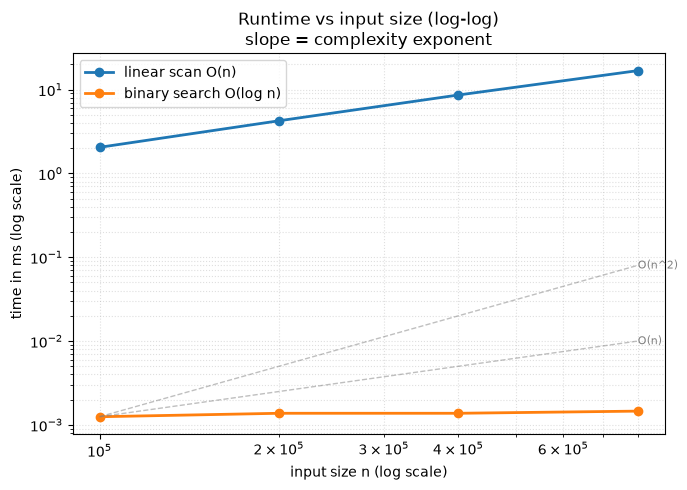

{'linear scan O(n)': [2.0487080328166485,
  4.247459000907838,
  8.62241699360311,
  16.837375005707145],
 'binary search O(log n)': [0.001250067725777626,
  0.001374981366097927,
  0.001374981366097927,
  0.001458916813135147]}

In [5]:
import os, sys
_root = os.getcwd()
for _ in range(5):
    if os.path.exists(os.path.join(_root, "bench_utils.py")):
        break
    _root = os.path.dirname(_root)
if _root not in sys.path:
    sys.path.insert(0, _root)
from bench_utils import benchmark

def make_worst_case(n):
    nums = list(range(0, 2 * n, 2))          # sorted, unique: 0, 2, 4, ...
    return (nums, 2 * n)                      # target above every element: absent, no early exit

solutions = {
    "linear scan O(n)": search_linear,
    "binary search O(log n)": search_binary,
}
sizes = [100_000, 200_000, 400_000, 800_000]

benchmark(solutions, make_worst_case, sizes, repeats=5, plot=True)

## 🧩 Patterns Learned

- **Pattern:** [Sorted Search](README.md) — this problem *is* the template: keep `[lo, hi]`, compare the middle, move `lo` or `hi` past `mid`, stop when the space is empty.
- **Invariant to say out loud:** "if the target exists, it is inside `nums[lo..hi]`". Every update (`lo = mid + 1`, `hi = mid - 1`) keeps that true and shrinks the space.
- **Signal:** "sorted array", "find the index / position", "must run in `O(log n)`".
- **Library form:** `i = bisect.bisect_left(nums, target)` then check `i < len(nums) and nums[i] == target`.
- **Related problems:** Search a 2D Matrix (flatten, then the same loop), Time Based Key-Value Store (last value `<= t`), Search Insert Position (return `lo` instead of `-1`), First Bad Version.
- **Common pitfalls:**
  1. `while lo < hi` with `hi = mid - 1` — skips the last remaining element (e.g. a single-element array).
  2. `lo = mid` or `hi = mid` in this inclusive form — the space can stop shrinking and the loop never ends.
  3. Starting with `hi = len(nums)` while also using `<=` — reads past the end of the array.
  4. Using it on unsorted data — the comparison no longer says which half is safe to discard.